In [9]:
from pathlib import Path
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path("..")
DATA_DIR = PROJECT_DIR / "data" / "raw"

STATIONS_FILE = DATA_DIR / "bike_stations_with_attributes.geojson"
WEATHER_FILE = DATA_DIR / "weather_data.csv"

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

print("Environment ready!")
print("Data directory:", DATA_DIR.resolve())

Environment ready!
Data directory: C:\Users\piotr\PycharmProjects\data\raw


In [10]:
stations = gpd.read_file(STATIONS_FILE)

DataSourceError: ..\data\raw\bike_stations_with_attributes.geojson: No such file or directory

In [11]:
for file in [STATIONS_FILE, WEATHER_FILE]:
    if file.exists():
        print(f"FOUND: {file.name}")
    else:
        print(f"MISSING: {file.name}")

MISSING: bike_stations_with_attributes.geojson
MISSING: weather_data.csv


In [12]:
stations = gpd.read_file(STATIONS_FILE)

print("Station dataset shape:", stations.shape)
print("\nColumn names:")
print(stations.columns.tolist())

print("\nFirst 5 rows:")
display(stations.head())

DataSourceError: ..\data\raw\bike_stations_with_attributes.geojson: No such file or directory

In [7]:
from pathlib import Path

print("Notebook working directory:")
print(Path.cwd())

print("\nFiles in this directory:")
for item in Path.cwd().iterdir():
    print(item.name)

Notebook working directory:
C:\Users\piotr\PycharmProjects\warsaw_bike_demand

Files in this directory:
.ipynb_checkpoints
.venv
02_data_anomalies.ipynb
app
data
models
notebooks
requirements.txt
src
Untitled.ipynb


In [8]:
from pathlib import Path

for path in Path.cwd().parent.rglob("bike_stations_with_attributes.geojson"):
    print("Found:", path.resolve())

Found: C:\Users\piotr\PycharmProjects\warsaw_bike_demand\data\raw\bike_stations_with_attributes.geojson


In [13]:
from pathlib import Path
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path(r"C:\Users\piotr\PycharmProjects\warsaw_bike_demand")
DATA_DIR = PROJECT_DIR / "data" / "raw"

STATIONS_FILE = DATA_DIR / "bike_stations_with_attributes.geojson"
WEATHER_FILE = DATA_DIR / "weather_data.csv"

print("Stations file exists:", STATIONS_FILE.exists())
print("Weather file exists:", WEATHER_FILE.exists())

Stations file exists: True
Weather file exists: True


In [14]:
stations = gpd.read_file(STATIONS_FILE)
weather = pd.read_csv(WEATHER_FILE)

print("Stations:", stations.shape)
print("Weather:", weather.shape)

Stations: (383, 23)
Weather: (129791, 7)


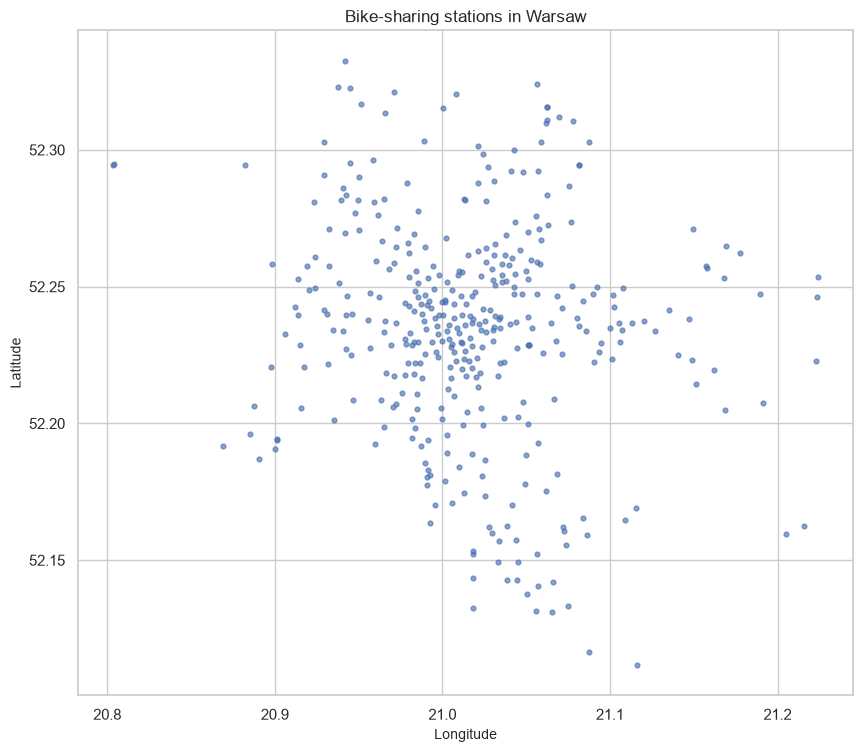

In [15]:
fig, ax = plt.subplots(figsize=(10, 10))

stations.plot(ax=ax, markersize=12, alpha=0.65)

ax.set_title("Bike-sharing stations in Warsaw")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()

In [16]:
print("Weather columns:")
print(weather.columns.tolist())

print("\nFirst 10 rows:")
display(weather.head(10))

print("\nData types:")
print(weather.dtypes)

print("\nMissing values:")
print(weather.isnull().sum())

Weather columns:
['2023-05-06 00:00', '52.30167214631459', '20.965925535033907', '6.9', 'Clear', '0.0', '15.5']

First 10 rows:


,2023-05-06 00:00,52.30167214631459,20.965925535033907,6.9,Clear,0.0,15.5
0,2023-05-06 01:00,52.301672,20.965926,6.4,Clear,0.0,15.5
1,2023-05-06 02:00,52.301672,20.965926,5.8,Clear,0.0,14.0
2,2023-05-06 03:00,52.301672,20.965926,5.5,Partly cloudy,0.0,13.0
3,2023-05-06 04:00,52.301672,20.965926,5.2,Partly cloudy,0.0,13.0
4,2023-05-06 05:00,52.301672,20.965926,4.3,Overcast,0.0,14.0
5,2023-05-06 06:00,52.301672,20.965926,5.4,Overcast,0.0,15.5
6,2023-05-06 07:00,52.301672,20.965926,6.9,Partly cloudy,0.0,16.6
7,2023-05-06 08:00,52.301672,20.965926,8.5,Partly cloudy,0.0,17.3
8,2023-05-06 09:00,52.301672,20.965926,9.8,Sunny,0.0,17.6
9,2023-05-06 10:00,52.301672,20.965926,10.7,Sunny,0.0,17.6



Data types:
2023-05-06 00:00          str
52.30167214631459     float64
20.965925535033907    float64
6.9                   float64
Clear                     str
0.0                   float64
15.5                  float64
dtype: object

Missing values:
2023-05-06 00:00      0
52.30167214631459     0
20.965925535033907    0
6.9                   0
Clear                 0
0.0                   0
15.5                  0
dtype: int64


In [17]:
weather = pd.read_csv(WEATHER_FILE, header=None)

weather.columns = [
    "datetime",
    "latitude",
    "longitude",
    "temperature",
    "weather_condition",
    "precipitation",
    "wind_speed"
]

print("Shape:", weather.shape)
display(weather.head(10))
print(weather.dtypes)

Shape: (129792, 7)


,datetime,latitude,longitude,temperature,weather_condition,precipitation,wind_speed
0,2023-05-06 00:00,52.301672,20.965926,6.9,Clear,0.0,15.5
1,2023-05-06 01:00,52.301672,20.965926,6.4,Clear,0.0,15.5
2,2023-05-06 02:00,52.301672,20.965926,5.8,Clear,0.0,14.0
3,2023-05-06 03:00,52.301672,20.965926,5.5,Partly cloudy,0.0,13.0
4,2023-05-06 04:00,52.301672,20.965926,5.2,Partly cloudy,0.0,13.0
5,2023-05-06 05:00,52.301672,20.965926,4.3,Overcast,0.0,14.0
6,2023-05-06 06:00,52.301672,20.965926,5.4,Overcast,0.0,15.5
7,2023-05-06 07:00,52.301672,20.965926,6.9,Partly cloudy,0.0,16.6
8,2023-05-06 08:00,52.301672,20.965926,8.5,Partly cloudy,0.0,17.3
9,2023-05-06 09:00,52.301672,20.965926,9.8,Sunny,0.0,17.6


datetime                 str
latitude             float64
longitude            float64
temperature          float64
weather_condition        str
precipitation        float64
wind_speed           float64
dtype: object


In [18]:
weather["datetime"] = pd.to_datetime(weather["datetime"])

print("Date range:")
print(weather["datetime"].min())
print(weather["datetime"].max())

print("\nWeather summary:")
display(weather.describe(include="all"))

Date range:
2023-05-06 00:00:00
2023-11-29 23:00:00

Weather summary:


,datetime,latitude,longitude,temperature,weather_condition,precipitation,wind_speed
count,129792,129792.000000,129792.000000,129792.000000,129792,129792.000000,129792.000000
unique,NaN,NaN,NaN,NaN,34,NaN,NaN
top,NaN,NaN,NaN,NaN,Partly cloudy,NaN,NaN
freq,NaN,NaN,NaN,NaN,29901,NaN,NaN
mean,2023-08-17 23:30:00,52.227441,21.055567,16.232494,NaN,0.077460,12.534662
min,2023-05-06 00:00:00,52.119395,20.886890,-5.200000,NaN,0.000000,0.000000
25%,2023-06-26 23:45:00,52.166852,20.963937,11.300000,NaN,0.000000,8.300000
50%,2023-08-17 23:30:00,52.212389,21.038197,17.000000,NaN,0.000000,11.500000
75%,2023-10-08 23:15:00,52.257928,21.112526,21.300000,NaN,0.000000,15.800000
max,2023-11-29 23:00:00,52.346611,21.256819,34.500000,NaN,7.900000,43.600000


In [19]:
print("Unique weather coordinates:")
print(
    weather[["latitude", "longitude"]]
    .drop_duplicates()
    .shape[0]
)

print("\nMost common coordinates:")
display(
    weather.groupby(["latitude", "longitude"])
    .size()
    .sort_values(ascending=False)
    .head(10)
)

Unique weather coordinates:
26

Most common coordinates:


latitude   longitude
52.119395  21.104014    4992
52.120676  21.031011    4992
52.161631  21.252268    4992
52.163004  21.179204    4992
52.164332  21.106133    4992
52.165615  21.033057    4992
52.166852  20.959976    4992
52.168044  20.886890    4992
52.206563  21.254540    4992
52.207939  21.181402    4992
dtype: int64

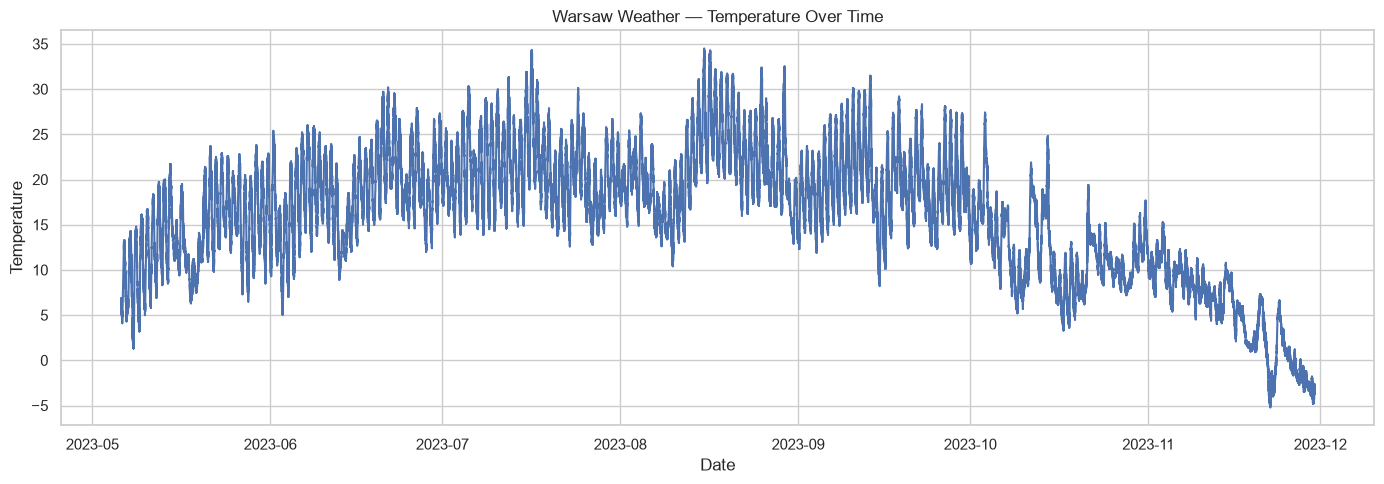

In [20]:
weather = weather.sort_values("datetime")

plt.figure(figsize=(14, 5))
plt.plot(weather["datetime"], weather["temperature"])

plt.title("Warsaw Weather — Temperature Over Time")
plt.xlabel("Date")
plt.ylabel("Temperature")
plt.grid(True)
plt.tight_layout()
plt.show()

In [21]:
print("Unique timestamps:", weather["datetime"].nunique())

print("Observations per timestamp:")
display(weather.groupby("datetime").size().value_counts())

print("Duplicate location/timestamp pairs:",
      weather.duplicated(["datetime", "latitude", "longitude"]).sum())

Unique timestamps: 4992
Observations per timestamp:


26    4992
Name: count, dtype: int64

Duplicate location/timestamp pairs: 0


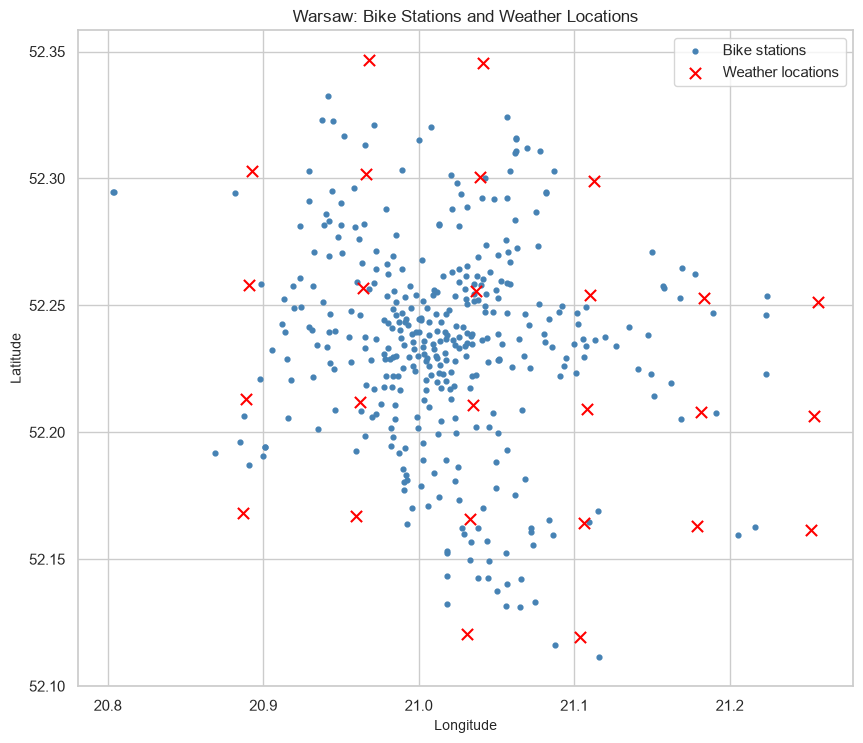

In [22]:
fig, ax = plt.subplots(figsize=(10, 10))

stations.plot(
    ax=ax,
    color="steelblue",
    markersize=12,
    label="Bike stations"
)

ax.scatter(
    weather["longitude"].drop_duplicates().values,
    weather.drop_duplicates(["latitude", "longitude"])["latitude"],
    color="red",
    marker="x",
    s=65,
    label="Weather locations"
)

ax.set_title("Warsaw: Bike Stations and Weather Locations")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend()
plt.show()

In [25]:
for file in DATA_DIR.iterdir():
    size_mb = file.stat().st_size / (1024 * 1024)

    print(
        f"{file.name:45} "
        f"{size_mb:10.2f} MB"
    )

bike_stations_with_attributes.geojson               0.23 MB
stations.rar                                     1590.40 MB
warszawa_centroidy_5km.geojson                      0.00 MB
warszawa_siatka_5km.geojson                         0.01 MB
weather_data.csv                                    9.83 MB


In [26]:
print("Unique timestamps:", weather["datetime"].nunique())

print("Observations per timestamp:")
display(weather.groupby("datetime").size().value_counts())

print("Duplicate pairs:",
      weather.duplicated(
          ["datetime", "latitude", "longitude"]
      ).sum())

Unique timestamps: 4992
Observations per timestamp:


26    4992
Name: count, dtype: int64

Duplicate pairs: 0


In [27]:
from pathlib import Path
import json

SAMPLE_DIR = PROJECT_DIR / "data" / "sample"

files = sorted(SAMPLE_DIR.iterdir())

for file in files:
    print(file.name, file.stat().st_size, "bytes")

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'C:\\Users\\piotr\\PycharmProjects\\warsaw_bike_demand\\data\\sample'

In [28]:
from pathlib import Path
import json

SAMPLE_DIR = PROJECT_DIR / "data" / "raw" / "sample"

files = sorted(p for p in SAMPLE_DIR.iterdir() if p.is_file())

for file in files:
    print(file.name, file.stat().st_size, "bytes")

output_1.json 833955 bytes
output_2.json 825980 bytes
output_3.json 824458 bytes


In [29]:
sample_file = files[0]

with open(sample_file, "r", encoding="utf-8") as f:
    sample_data = json.load(f)

print("Python data type:", type(sample_data))

if isinstance(sample_data, dict):
    print("JSON keys:", sample_data.keys())
elif isinstance(sample_data, list):
    print("Number of records:", len(sample_data))
    print("First record:", sample_data[0])
else:
    print(sample_data)

Python data type: <class 'dict'>
JSON keys: dict_keys(['year', 'month', 'day', 'hour', 'minute', 'stations_data'])


In [30]:
print("Timestamp:")
print({
    "year": sample_data["year"],
    "month": sample_data["month"],
    "day": sample_data["day"],
    "hour": sample_data["hour"],
    "minute": sample_data["minute"]
})

print("\nStations data type:", type(sample_data["stations_data"]))
print("Number of stations:", len(sample_data["stations_data"]))

print("\nFirst station record:")
print(sample_data["stations_data"][0])

Timestamp:
{'year': 2023, 'month': 5, 'day': 6, 'hour': 9, 'minute': 0}

Stations data type: <class 'list'>
Number of stations: 383

First station record:
{'uid': '448565', 'name': 'Nestle House', 'number': 6413, 'placeType': 'STATION', 'terminalType': 'STATION_4G', 'geoCoords': {'lat': 52.183992, 'lng': 21.00984}, 'availabilityStatus': {'bikes': 8, 'bookedBikes': 0, 'availableBikes': 8, 'bikeRacks': 15, 'freeRacks': 7, 'freeSpecialRacks': 0}, 'bikes': [{'number': 612693, 'bikeType': 'STANDARD_4G', 'battery': None}, {'number': 612441, 'bikeType': 'STANDARD_4G', 'battery': None}, {'number': 612421, 'bikeType': 'STANDARD_4G', 'battery': None}, {'number': 612010, 'bikeType': 'STANDARD_4G', 'battery': None}, {'number': 611348, 'bikeType': 'STANDARD_4G', 'battery': None}, {'number': 610883, 'bikeType': 'STANDARD_4G', 'battery': None}, {'number': 610863, 'bikeType': 'STANDARD_4G', 'battery': None}, {'number': 610351, 'bikeType': 'STANDARD_4G', 'battery': None}], 'bikeTypes': [{'name': 'STAND

In [31]:
first_station = sample_data["stations_data"][0]

print("Available fields:")
print(first_station.keys())

Available fields:
dict_keys(['uid', 'name', 'number', 'placeType', 'terminalType', 'geoCoords', 'availabilityStatus', 'bikes', 'bikeTypes', 'centroid_latitude', 'centroid_longitude'])


In [32]:
from datetime import datetime
import pandas as pd

def parse_snapshot(data):
    # Build timestamp from the JSON fields
    timestamp = datetime(
        data["year"],
        data["month"],
        data["day"],
        data["hour"],
        data["minute"]
    )

    rows = []

    for station in data["stations_data"]:
        availability = station["availabilityStatus"]
        coordinates = station["geoCoords"]

        rows.append({
            "timestamp": timestamp,
            "station_id": station["uid"],
            "station_name": station["name"],
            "latitude": coordinates["lat"],
            "longitude": coordinates["lng"],
            "bikes": availability["bikes"],
            "booked_bikes": availability["bookedBikes"],
            "available_bikes": availability["availableBikes"],
            "bike_racks": availability["bikeRacks"],
            "free_racks": availability["freeRacks"]
        })

    return pd.DataFrame(rows)


snapshot_df = parse_snapshot(sample_data)

print("Shape:", snapshot_df.shape)
display(snapshot_df.head())

Shape: (383, 10)


,timestamp,station_id,station_name,latitude,longitude,bikes,booked_bikes,available_bikes,bike_racks,free_racks
0,2023-05-06 09:00:00,448565,Nestle House,52.183992,21.009840,8,0,8,15,7
1,2023-05-06 09:00:00,2585259,UKSW,52.296226,20.958327,10,0,10,10,0
2,2023-05-06 09:00:00,2585263,Metro Młociny,52.290974,20.929556,16,0,16,12,0
3,2023-05-06 09:00:00,2585265,Marymoncka - Dewajtis,52.290173,20.950370,9,0,9,10,1
4,2023-05-06 09:00:00,2585267,Metro Wawrzyszew,52.285914,20.940561,17,0,17,10,0


In [33]:
import json

all_snapshots = []

for file in files:
    with open(file, "r", encoding="utf-8") as f:
        data = json.load(f)

    df = parse_snapshot(data)
    all_snapshots.append(df)

sample_df = pd.concat(all_snapshots, ignore_index=True)

print("Combined shape:", sample_df.shape)
print("Unique timestamps:", sample_df["timestamp"].nunique())
print("Unique stations:", sample_df["station_id"].nunique())

display(sample_df.head())

Combined shape: (1141, 10)
Unique timestamps: 3
Unique stations: 391


,timestamp,station_id,station_name,latitude,longitude,bikes,booked_bikes,available_bikes,bike_racks,free_racks
0,2023-05-06 09:00:00,448565,Nestle House,52.183992,21.009840,8,0,8,15,7
1,2023-05-06 09:00:00,2585259,UKSW,52.296226,20.958327,10,0,10,10,0
2,2023-05-06 09:00:00,2585263,Metro Młociny,52.290974,20.929556,16,0,16,12,0
3,2023-05-06 09:00:00,2585265,Marymoncka - Dewajtis,52.290173,20.950370,9,0,9,10,1
4,2023-05-06 09:00:00,2585267,Metro Wawrzyszew,52.285914,20.940561,17,0,17,10,0


In [34]:
print("Missing values:")
print(sample_df.isnull().sum())

print("\nDuplicate station-timestamp records:",
      sample_df.duplicated(["timestamp", "station_id"]).sum())

print("\nBike availability summary:")
print(sample_df["available_bikes"].describe())

print("\nStations with zero available bikes:",
      (sample_df["available_bikes"] == 0).sum())

Missing values:
timestamp          0
station_id         0
station_name       0
latitude           0
longitude          0
bikes              0
booked_bikes       0
available_bikes    0
bike_racks         0
free_racks         0
dtype: int64

Duplicate station-timestamp records: 0

Bike availability summary:
count    1141.000000
mean        7.652060
std         6.430797
min         0.000000
25%         2.000000
50%         7.000000
75%        11.000000
max        38.000000
Name: available_bikes, dtype: float64

Stations with zero available bikes: 31


In [35]:
print("Stations per timestamp:")
print(
    sample_df.groupby("timestamp")["station_id"]
    .nunique()
)

print("\nSnapshot timestamps:")
print(sorted(sample_df["timestamp"].unique()))

print("\nRows per source file:")
for file in files:
    with open(file, "r", encoding="utf-8") as f:
        data = json.load(f)

    print(
        file.name,
        "timestamp:",
        f'{data["year"]}-{data["month"]:02d}-{data["day"]:02d} '
        f'{data["hour"]:02d}:{data["minute"]:02d}',
        "stations:",
        len(data["stations_data"])
    )

Stations per timestamp:
timestamp
2023-05-06 09:00:00    383
2023-05-06 09:05:00    380
2023-05-06 09:10:00    378
Name: station_id, dtype: int64

Snapshot timestamps:
[Timestamp('2023-05-06 09:00:00'), Timestamp('2023-05-06 09:05:00'), Timestamp('2023-05-06 09:10:00')]

Rows per source file:
output_1.json timestamp: 2023-05-06 09:00 stations: 383
output_2.json timestamp: 2023-05-06 09:05 stations: 380
output_3.json timestamp: 2023-05-06 09:10 stations: 378


In [36]:
stockouts = sample_df[
    sample_df["available_bikes"] == 0
]

print("Total zero-bike observations:", len(stockouts))

print(
    "Distinct stations with at least one zero-bike observation:",
    stockouts["station_id"].nunique()
)

print("\nStockouts by timestamp:")
print(
    stockouts.groupby("timestamp").size()
)

print("\nStations with most stockout observations:")
print(
    stockouts.groupby("station_name").size()
    .sort_values(ascending=False)
)

Total zero-bike observations: 31
Distinct stations with at least one zero-bike observation: 14

Stockouts by timestamp:
timestamp
2023-05-06 09:00:00    10
2023-05-06 09:05:00    10
2023-05-06 09:10:00    11
dtype: int64

Stations with most stockout observations:
station_name
Plac Narutowicza                      3
Plac Konstytucji                      3
al. Prymasa Tysiąclecia - Obozowa     3
Żelazna - Sienna                      3
al. Jana Pawła II - Złota             3
Radzymińska - Trocka                  3
Żwirki i Wigury - Racławicka          3
Redutowa - Pustola                    2
Jana Olbrachta - Antka Rozpylacza     2
Puławska - Dworkowa                   2
Metro Bemowo                          1
Marszałkowska - Hoża                  1
Raszyńska - Wawelska                  1
Żwirki i Wigury - Księcia Trojdena    1
dtype: int64


In [37]:
snapshot_ids = set(sample_df["station_id"].astype(str))
metadata_ids = set(stations["uid"].astype(str))

print("Snapshot station IDs:", len(snapshot_ids))
print("Metadata station IDs:", len(metadata_ids))

print("IDs present in snapshots but missing from metadata:",
      len(snapshot_ids - metadata_ids))

print("IDs present in metadata but missing from snapshots:",
      len(metadata_ids - snapshot_ids))

Snapshot station IDs: 391
Metadata station IDs: 383
IDs present in snapshots but missing from metadata: 8
IDs present in metadata but missing from snapshots: 0


In [38]:
# identify 8 unmatched stations 
metadata_ids = set(stations["uid"].astype(str))

unmatched_stations = (
    sample_df[
        ~sample_df["station_id"].astype(str).isin(metadata_ids)
    ][
        ["station_id", "station_name", "latitude", "longitude"]
    ]
    .drop_duplicates("station_id")
    .sort_values("station_name")
)

print("Unmatched stations:", len(unmatched_stations))
display(unmatched_stations)

Unmatched stations: 8


,station_id,station_name,latitude,longitude
760,181510617,BIKE 611631,52.235302,21.031022
761,181510863,BIKE 613016,52.227524,21.019524
1140,181514006,BIKE 613016,52.227560,21.020520
1137,181512333,BIKE 613033,52.221329,21.001880
1138,181513276,BIKE 613122,52.237711,21.033044
1139,181513324,BIKE 613321,52.264849,20.985140
762,181511403,BIKE 613581,52.322898,20.936649
759,181510346,BIKE 613802,52.143311,21.019593


In [39]:
print("Duplicate metadata IDs:", stations["uid"].duplicated().sum())

print("Metadata ID data type:", stations["uid"].dtype)
print("Snapshot ID data type:", sample_df["station_id"].dtype)

Duplicate metadata IDs: 0
Metadata ID data type: int32
Snapshot ID data type: str


In [40]:
import json
import pandas as pd

unmatched_ids = set(unmatched_stations["station_id"].astype(str))

unmatched_details = []

for file in files:
    with open(file, "r", encoding="utf-8") as f:
        data = json.load(f)

    timestamp = pd.Timestamp(
        year=data["year"],
        month=data["month"],
        day=data["day"],
        hour=data["hour"],
        minute=data["minute"]
    )

    for station in data["stations_data"]:
        if str(station["uid"]) in unmatched_ids:
            availability = station["availabilityStatus"]

            unmatched_details.append({
                "timestamp": timestamp,
                "uid": station["uid"],
                "name": station["name"],
                "number": station["number"],
                "placeType": station["placeType"],
                "terminalType": station["terminalType"],
                "latitude": station["geoCoords"]["lat"],
                "longitude": station["geoCoords"]["lng"],
                "available_bikes": availability["availableBikes"],
                "free_racks": availability["freeRacks"]
            })

unmatched_df = pd.DataFrame(unmatched_details)

display(unmatched_df.sort_values(["uid", "timestamp"]))


,timestamp,uid,name,number,placeType,terminalType,latitude,longitude,available_bikes,free_racks
0,2023-05-06 09:05:00,181510346,BIKE 613802,0,FREESTANDING_ELECTRIC_BIKE,UNKNOWN,52.143311,21.019593,1,0
4,2023-05-06 09:10:00,181510346,BIKE 613802,0,FREESTANDING_ELECTRIC_BIKE,UNKNOWN,52.143311,21.019593,1,0
1,2023-05-06 09:05:00,181510617,BIKE 611631,0,FREESTANDING_BIKE,UNKNOWN,52.235302,21.031022,1,0
5,2023-05-06 09:10:00,181510617,BIKE 611631,0,FREESTANDING_BIKE,UNKNOWN,52.235302,21.031022,1,0
2,2023-05-06 09:05:00,181510863,BIKE 613016,0,FREESTANDING_BIKE,UNKNOWN,52.227524,21.019524,1,0
3,2023-05-06 09:05:00,181511403,BIKE 613581,0,FREESTANDING_ELECTRIC_BIKE,UNKNOWN,52.322898,20.936649,1,0
6,2023-05-06 09:10:00,181511403,BIKE 613581,0,FREESTANDING_ELECTRIC_BIKE,UNKNOWN,52.322898,20.936649,1,0
7,2023-05-06 09:10:00,181512333,BIKE 613033,0,FREESTANDING_BIKE,UNKNOWN,52.221329,21.001880,1,0
8,2023-05-06 09:10:00,181513276,BIKE 613122,0,FREESTANDING_BIKE,UNKNOWN,52.237711,21.033044,1,0
9,2023-05-06 09:10:00,181513324,BIKE 613321,0,FREESTANDING_BIKE,UNKNOWN,52.264849,20.985140,1,0


In [41]:
print(
    unmatched_df.groupby(["uid", "name"])
    .agg(
        observations=("timestamp", "count"),
        first_seen=("timestamp", "min"),
        last_seen=("timestamp", "max"),
        avg_bikes=("available_bikes", "mean")
    )
    .reset_index()
)

         uid         name  observations          first_seen  \
0  181510346  BIKE 613802             2 2023-05-06 09:05:00   
1  181510617  BIKE 611631             2 2023-05-06 09:05:00   
2  181510863  BIKE 613016             1 2023-05-06 09:05:00   
3  181511403  BIKE 613581             2 2023-05-06 09:05:00   
4  181512333  BIKE 613033             1 2023-05-06 09:10:00   
5  181513276  BIKE 613122             1 2023-05-06 09:10:00   
6  181513324  BIKE 613321             1 2023-05-06 09:10:00   
7  181514006  BIKE 613016             1 2023-05-06 09:10:00   

            last_seen  avg_bikes  
0 2023-05-06 09:10:00        1.0  
1 2023-05-06 09:10:00        1.0  
2 2023-05-06 09:05:00        1.0  
3 2023-05-06 09:10:00        1.0  
4 2023-05-06 09:10:00        1.0  
5 2023-05-06 09:10:00        1.0  
6 2023-05-06 09:10:00        1.0  
7 2023-05-06 09:10:00        1.0  


In [42]:
# similarly to wroclaw, there are freestanding bikes, never returned to exact station


In [43]:
def parse_snapshot(data):
    timestamp = datetime(
        data["year"],
        data["month"],
        data["day"],
        data["hour"],
        data["minute"]
    )

    rows = []

    for item in data["stations_data"]:
        availability = item["availabilityStatus"]
        coordinates = item["geoCoords"]

        terminal_type = item["terminalType"]
        place_type = item["placeType"]

        if place_type == "STATION":
            entity_type = "station"
        elif "FREESTANDING" in terminal_type:
            entity_type = "freestanding_bike"
        else:
            entity_type = "other"

        rows.append({
            "timestamp": timestamp,
            "entity_type": entity_type,
            "station_id": str(item["uid"]),
            "name": item["name"],
            "place_type": place_type,
            "terminal_type": terminal_type,
            "latitude": coordinates["lat"],
            "longitude": coordinates["lng"],
            "bikes": availability["bikes"],
            "available_bikes": availability["availableBikes"],
            "bike_racks": availability["bikeRacks"],
            "free_racks": availability["freeRacks"]
        })

    return pd.DataFrame(rows)

In [44]:
all_snapshots = []

for file in files:
    with open(file, "r", encoding="utf-8") as f:
        data = json.load(f)

    all_snapshots.append(parse_snapshot(data))

sample_all_df = pd.concat(all_snapshots, ignore_index=True)

print("All records:", sample_all_df.shape)

print("\nRecords by entity type:")
print(sample_all_df["entity_type"].value_counts())

print("\nTerminal types:")
print(sample_all_df["terminal_type"].value_counts())

All records: (1141, 12)

Records by entity type:
entity_type
station    930
other      211
Name: count, dtype: int64

Terminal types:
terminal_type
STATION_4G    930
UNKNOWN       211
Name: count, dtype: int64


In [45]:
sample_stations_df = sample_all_df[
    sample_all_df["entity_type"] == "station"
].copy()

sample_bikes_df = sample_all_df[
    sample_all_df["entity_type"] == "freestanding_bike"
].copy()

print("Docking station observations:", len(sample_stations_df))
print("Freestanding bike observations:", len(sample_bikes_df))

print(
    "\nUnique docking stations:",
    sample_stations_df["station_id"].nunique()
)

print(
    "Unique freestanding bike IDs:",
    sample_bikes_df["station_id"].nunique()
)

Docking station observations: 930
Freestanding bike observations: 0

Unique docking stations: 310
Unique freestanding bike IDs: 0


In [46]:
from collections import Counter

place_types = Counter()
terminal_types = Counter()
examples = []

for file in files:
    with open(file, "r", encoding="utf-8") as f:
        data = json.load(f)

    for item in data["stations_data"]:
        place_types[str(item.get("placeType"))] += 1
        terminal_types[str(item.get("terminalType"))] += 1

        if item.get("terminalType") != "STATION_4G":
            examples.append({
                "uid": item.get("uid"),
                "name": item.get("name"),
                "placeType": item.get("placeType"),
                "terminalType": item.get("terminalType"),
                "geoCoords": item.get("geoCoords"),
                "availabilityStatus": item.get("availabilityStatus")
            })

print("Place types:", place_types)
print("\nTerminal types:", terminal_types)

print("\nFirst 5 non-standard records:")
for example in examples[:5]:
    print(example)

Place types: Counter({'STATION': 930, 'FREESTANDING_BIKE': 151, 'FREESTANDING_ELECTRIC_BIKE': 60})

Terminal types: Counter({'STATION_4G': 930, 'UNKNOWN': 211})

First 5 non-standard records:
{'uid': '181013001', 'name': 'BIKE 610038', 'placeType': 'FREESTANDING_BIKE', 'terminalType': 'UNKNOWN', 'geoCoords': {'lat': 52.282178, 'lng': 20.96508}, 'availabilityStatus': {'bikes': 1, 'bookedBikes': 0, 'availableBikes': 1, 'bikeRacks': 0, 'freeRacks': 0, 'freeSpecialRacks': 0}}
{'uid': '181027943', 'name': 'BIKE 613841', 'placeType': 'FREESTANDING_ELECTRIC_BIKE', 'terminalType': 'UNKNOWN', 'geoCoords': {'lat': 52.294556, 'lng': 20.803693}, 'availabilityStatus': {'bikes': 1, 'bookedBikes': 0, 'availableBikes': 1, 'bikeRacks': 0, 'freeRacks': 0, 'freeSpecialRacks': 0}}
{'uid': '181083059', 'name': 'BIKE 610823', 'placeType': 'FREESTANDING_BIKE', 'terminalType': 'UNKNOWN', 'geoCoords': {'lat': 52.310804, 'lng': 21.062593}, 'availabilityStatus': {'bikes': 1, 'bookedBikes': 0, 'availableBikes': 1

In [47]:
for item in examples:
    if str(item["uid"]) in unmatched_ids:
        print(item)
        

{'uid': '181510346', 'name': 'BIKE 613802', 'placeType': 'FREESTANDING_ELECTRIC_BIKE', 'terminalType': 'UNKNOWN', 'geoCoords': {'lat': 52.143311, 'lng': 21.019593}, 'availabilityStatus': {'bikes': 1, 'bookedBikes': 0, 'availableBikes': 1, 'bikeRacks': 0, 'freeRacks': 0, 'freeSpecialRacks': 0}}
{'uid': '181510617', 'name': 'BIKE 611631', 'placeType': 'FREESTANDING_BIKE', 'terminalType': 'UNKNOWN', 'geoCoords': {'lat': 52.235302, 'lng': 21.031022}, 'availabilityStatus': {'bikes': 1, 'bookedBikes': 0, 'availableBikes': 1, 'bikeRacks': 0, 'freeRacks': 0, 'freeSpecialRacks': 0}}
{'uid': '181510863', 'name': 'BIKE 613016', 'placeType': 'FREESTANDING_BIKE', 'terminalType': 'UNKNOWN', 'geoCoords': {'lat': 52.227524, 'lng': 21.019524}, 'availabilityStatus': {'bikes': 1, 'bookedBikes': 0, 'availableBikes': 1, 'bikeRacks': 0, 'freeRacks': 0, 'freeSpecialRacks': 0}}
{'uid': '181511403', 'name': 'BIKE 613581', 'placeType': 'FREESTANDING_ELECTRIC_BIKE', 'terminalType': 'UNKNOWN', 'geoCoords': {'lat'

In [48]:
def parse_snapshot(data):
    timestamp = datetime(
        data["year"],
        data["month"],
        data["day"],
        data["hour"],
        data["minute"]
    )

    rows = []

    for item in data["stations_data"]:
        availability = item["availabilityStatus"]
        coordinates = item["geoCoords"]

        place_type = item["placeType"]

        if place_type == "STATION":
            entity_type = "station"
        elif place_type == "FREESTANDING_BIKE":
            entity_type = "freestanding_bike"
        elif place_type == "FREESTANDING_ELECTRIC_BIKE":
            entity_type = "freestanding_electric_bike"
        else:
            entity_type = "other"

        rows.append({
            "timestamp": timestamp,
            "entity_type": entity_type,
            "station_id": str(item["uid"]),
            "name": item["name"],
            "place_type": place_type,
            "terminal_type": item["terminalType"],
            "latitude": coordinates["lat"],
            "longitude": coordinates["lng"],
            "bikes": availability["bikes"],
            "available_bikes": availability["availableBikes"],
            "bike_racks": availability["bikeRacks"],
            "free_racks": availability["freeRacks"]
        })

    return pd.DataFrame(rows)

In [49]:
all_snapshots = []

for file in files:
    with open(file, "r", encoding="utf-8") as f:
        data = json.load(f)

    all_snapshots.append(parse_snapshot(data))

sample_all_df = pd.concat(all_snapshots, ignore_index=True)

print("All records:", sample_all_df.shape)

print("\nRecords by entity type:")
print(sample_all_df["entity_type"].value_counts())

print("\nUnique IDs by entity type:")
print(
    sample_all_df.groupby("entity_type")["station_id"].nunique()
)

All records: (1141, 12)

Records by entity type:
entity_type
station                       930
freestanding_bike             151
freestanding_electric_bike     60
Name: count, dtype: int64

Unique IDs by entity type:
entity_type
freestanding_bike              57
freestanding_electric_bike     24
station                       310
Name: station_id, dtype: int64


In [50]:
sample_stations_df = sample_all_df[
    sample_all_df["entity_type"] == "station"
].copy()

sample_freestanding_df = sample_all_df[
    sample_all_df["entity_type"].isin([
        "freestanding_bike",
        "freestanding_electric_bike"
    ])
].copy()

print("Docking station observations:", len(sample_stations_df))
print("Freestanding bike observations:", len(sample_freestanding_df))

Docking station observations: 930
Freestanding bike observations: 211


In [51]:
print("Docking stations per timestamp:")
print(
    sample_stations_df.groupby("timestamp")["station_id"]
    .nunique()
)

print("\nMetadata stations:", stations["uid"].nunique())

station_ids = set(sample_stations_df["station_id"].astype(str))
metadata_ids = set(stations["uid"].astype(str))

print("\nDocking station IDs missing from metadata:",
      len(station_ids - metadata_ids))

print("Metadata IDs not observed as docking stations:",
      len(metadata_ids - station_ids))

Docking stations per timestamp:
timestamp
2023-05-06 09:00:00    310
2023-05-06 09:05:00    310
2023-05-06 09:10:00    310
Name: station_id, dtype: int64

Metadata stations: 383

Docking station IDs missing from metadata: 0
Metadata IDs not observed as docking stations: 73


In [52]:
freestanding_ids = set(
    sample_freestanding_df["station_id"].astype(str)
)

print("Metadata IDs:", len(metadata_ids))
print("Docking station IDs:", len(station_ids))
print("Freestanding bike IDs:", len(freestanding_ids))

print(
    "\nMetadata IDs also appearing as freestanding bikes:",
    len(metadata_ids & freestanding_ids)
)

print(
    "Metadata IDs absent from all snapshot records:",
    len(metadata_ids - station_ids - freestanding_ids)
)

print(
    "Freestanding IDs absent from metadata:",
    len(freestanding_ids - metadata_ids)
)

Metadata IDs: 383
Docking station IDs: 310
Freestanding bike IDs: 81

Metadata IDs also appearing as freestanding bikes: 73
Metadata IDs absent from all snapshot records: 0
Freestanding IDs absent from metadata: 8


In [53]:
%pip install rarfile

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [54]:
from pathlib import Path
import rarfile
import json

STATIONS_ARCHIVE = DATA_DIR / "stations.rar"

print("Archive exists:", STATIONS_ARCHIVE.exists())
print("Archive size (GB):",
      round(STATIONS_ARCHIVE.stat().st_size / 1024**3, 2))

Archive exists: True
Archive size (GB): 1.55


In [55]:
rf = rarfile.RarFile(STATIONS_ARCHIVE)

members = [
    item for item in rf.infolist()
    if not item.is_dir() and item.filename.lower().endswith(".json")
]

print("Number of JSON files:", len(members))
print("\nFirst five archive members:")

for item in members[:5]:
    print(item.filename, item.file_size, "bytes")

Number of JSON files: 59694

First five archive members:
stations/output_1.json 833955 bytes
stations/output_10.json 815859 bytes
stations/output_100.json 852323 bytes
stations/output_1000.json 813956 bytes
stations/output_10000.json 873311 bytes


In [56]:
first_member = members[0]

with rf.open(first_member) as f:
    test_data = json.load(f)

print("Timestamp:", {
    "year": test_data["year"],
    "month": test_data["month"],
    "day": test_data["day"],
    "hour": test_data["hour"],
    "minute": test_data["minute"]
})

print("Number of records:", len(test_data["stations_data"]))

RarCannotExec: Cannot find working tool

In [57]:
import shutil
import rarfile

seven_zip = shutil.which("7z") or shutil.which("7zz")

print("7-Zip found at:", seven_zip)

7-Zip found at: None


In [58]:
from pathlib import Path

candidates = [
    Path(r"C:\Program Files\7-Zip\7z.exe"),
    Path(r"C:\Program Files (x86)\7-Zip\7z.exe"),
]

seven_zip = next((p for p in candidates if p.exists()), None)

print("7-Zip found at:", seven_zip)

7-Zip found at: C:\Program Files\7-Zip\7z.exe


In [59]:
rarfile.UNRAR_TOOL = str(seven_zip)
rarfile.tool_setup(force=True)

In [60]:
import json

rf = rarfile.RarFile(STATIONS_ARCHIVE)

members = [
    item for item in rf.infolist()
    if not item.is_dir() and item.filename.lower().endswith(".json")
]

print("Number of JSON files:", len(members))
print("First five files:", [item.filename for item in members[:5]])

with rf.open(members[0]) as f:
    test_data = json.load(f)

print("Timestamp:", {
    key: test_data[key]
    for key in ["year", "month", "day", "hour", "minute"]
})
print("Records in snapshot:", len(test_data["stations_data"]))

Number of JSON files: 59694
First five files: ['stations/output_1.json', 'stations/output_10.json', 'stations/output_100.json', 'stations/output_1000.json', 'stations/output_10000.json']


BadRarFile: Failed the read enough data: req=833955 got=124

In [61]:
import subprocess
from pathlib import Path

seven_zip = r"C:\Program Files\7-Zip\7z.exe"

result = subprocess.run(
    [seven_zip, "t", str(STATIONS_ARCHIVE)],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-2000:])
print(result.stderr[-1000:])

Return code: 0

7-Zip 26.06 (x64) : Copyright (c) 1999-2026 Igor Pavlov : 2026-11-06

Scanning the drive for archives:
1 file, 1667650137 bytes (1591 MiB)

Testing archive: C:\Users\piotr\PycharmProjects\warsaw_bike_demand\data\raw\stations.rar
--
Path = C:\Users\piotr\PycharmProjects\warsaw_bike_demand\data\raw\stations.rar
Type = Rar5
Physical Size = 1667650137
Characteristics = Locator QuickOpen:1663313426
Encrypted = -
Solid = -
Blocks = 59695
Method = v6:1M:m3
Multivolume = -
Volumes = 1

Everything is Ok

Folders: 1
Files: 59694
Size:       48385629093
Compressed: 1667650137




In [62]:
import json
import subprocess

member_name = members[0].filename

result = subprocess.run(
    [
        seven_zip,
        "x",
        "-so",
        str(STATIONS_ARCHIVE),
        member_name
    ],
    capture_output=True
)

print("Return code:", result.returncode)
print("Bytes received:", len(result.stdout))
print("Error output:", result.stderr.decode(errors="replace")[-1000:])

if result.returncode == 0:
    test_data = json.loads(result.stdout)

    print("Timestamp:", {
        key: test_data[key]
        for key in ["year", "month", "day", "hour", "minute"]
    })
    print("Records:", len(test_data["stations_data"]))

Return code: 0
Bytes received: 833955
Error output: 
Timestamp: {'year': 2023, 'month': 5, 'day': 6, 'hour': 9, 'minute': 0}
Records: 383


In [63]:
import subprocess
import json

test_members = [
    "stations/output_1.json",
    "stations/output_2.json",
    "stations/output_3.json"
]

result = subprocess.run(
    [seven_zip, "x", "-so", str(STATIONS_ARCHIVE), *test_members],
    capture_output=True
)

print("Return code:", result.returncode)
print("Output size:", len(result.stdout))

# Check whether the concatenated JSON documents can be decoded individually
decoder = json.JSONDecoder()
content = result.stdout.decode("utf-8")
position = 0
timestamps = []

while position < len(content):
    while position < len(content) and content[position].isspace():
        position += 1

    if position >= len(content):
        break

    data, position = decoder.raw_decode(content, position)

    timestamps.append(
        (data["year"], data["month"], data["day"],
         data["hour"], data["minute"])
    )

print("Snapshots decoded:", len(timestamps))
print("Timestamps:", timestamps)

Return code: 0
Output size: 2484393
Snapshots decoded: 3
Timestamps: [(2023, 5, 6, 9, 0), (2023, 5, 6, 9, 5), (2023, 5, 6, 9, 10)]


In [64]:
from pathlib import Path
import subprocess
import json

# Sort archive members numerically: 1, 2, 3, ..., 10, 11, ...
members_sorted = sorted(
    members,
    key=lambda item: int(
        Path(item.filename).stem.split("_")[-1]
    )
)

print("First five:", [m.filename for m in members_sorted[:5]])
print("Last five:", [m.filename for m in members_sorted[-5:]])

# Read the first 24 snapshots directly from the archive
test_batch = [m.filename for m in members_sorted[:24]]

result = subprocess.run(
    [seven_zip, "x", "-so", str(STATIONS_ARCHIVE), *test_batch],
    capture_output=True
)

if result.returncode != 0:
    raise RuntimeError(result.stderr.decode(errors="replace"))

decoder = json.JSONDecoder()
content = result.stdout.decode("utf-8")
position = 0
test_timestamps = []

while position < len(content):
    while position < len(content) and content[position].isspace():
        position += 1

    if position >= len(content):
        break

    data, position = decoder.raw_decode(content, position)

    test_timestamps.append(
        f"{data['year']}-{data['month']:02d}-{data['day']:02d} "
        f"{data['hour']:02d}:{data['minute']:02d}"
    )

print("Decoded snapshots:", len(test_timestamps))
print("First timestamps:", test_timestamps[:5])
print("Last timestamps:", test_timestamps[-5:])

First five: ['stations/output_1.json', 'stations/output_2.json', 'stations/output_3.json', 'stations/output_4.json', 'stations/output_5.json']
Last five: ['stations/output_59690.json', 'stations/output_59691.json', 'stations/output_59692.json', 'stations/output_59693.json', 'stations/output_59694.json']
Decoded snapshots: 24
First timestamps: ['2023-05-06 09:00', '2023-05-06 09:45', '2023-05-06 09:50', '2023-05-06 09:55', '2023-05-06 10:00']
Last timestamps: ['2023-05-06 09:20', '2023-05-06 09:25', '2023-05-06 09:30', '2023-05-06 09:35', '2023-05-06 09:40']


In [65]:
decoder = json.JSONDecoder()

for member in members_sorted[:24]:
    result = subprocess.run(
        [seven_zip, "x", "-so", str(STATIONS_ARCHIVE), member.filename],
        capture_output=True
    )

    if result.returncode != 0:
        print("ERROR:", member.filename)
        continue

    data = json.loads(result.stdout)

    timestamp = (
        f"{data['year']}-{data['month']:02d}-{data['day']:02d} "
        f"{data['hour']:02d}:{data['minute']:02d}"
    )

    print(member.filename, "->", timestamp)

stations/output_1.json -> 2023-05-06 09:00
stations/output_2.json -> 2023-05-06 09:05
stations/output_3.json -> 2023-05-06 09:10
stations/output_4.json -> 2023-05-06 09:15
stations/output_5.json -> 2023-05-06 09:20
stations/output_6.json -> 2023-05-06 09:25
stations/output_7.json -> 2023-05-06 09:30
stations/output_8.json -> 2023-05-06 09:35
stations/output_9.json -> 2023-05-06 09:40
stations/output_10.json -> 2023-05-06 09:45
stations/output_11.json -> 2023-05-06 09:50
stations/output_12.json -> 2023-05-06 09:55
stations/output_13.json -> 2023-05-06 10:00
stations/output_14.json -> 2023-05-06 10:05
stations/output_15.json -> 2023-05-06 10:10
stations/output_16.json -> 2023-05-06 10:15
stations/output_17.json -> 2023-05-06 10:20
stations/output_18.json -> 2023-05-06 10:25
stations/output_19.json -> 2023-05-06 10:30
stations/output_20.json -> 2023-05-06 10:35
stations/output_21.json -> 2023-05-06 10:40
stations/output_22.json -> 2023-05-06 10:45
stations/output_23.json -> 2023-05-06 10:

In [66]:
from pathlib import Path

# Project root is the parent of the notebooks folder
PROJECT_DIR = Path.cwd().parent

DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

STATIONS_ARCHIVE = DATA_DIR / "stations.rar"
STATIONS_FILE = DATA_DIR / "bike_stations_with_attributes.geojson"
WEATHER_FILE = DATA_DIR / "weather_data.csv"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

DB_FILE = PROCESSED_DIR / "bike_hourly.sqlite"

print("Project directory:", PROJECT_DIR)
print("Archive exists:", STATIONS_ARCHIVE.exists())
print("Output directory:", PROCESSED_DIR)

Project directory: C:\Users\piotr\PycharmProjects
Archive exists: False
Output directory: C:\Users\piotr\PycharmProjects\data\processed


In [67]:
from pathlib import Path

# Project root is the parent of the notebooks folder
PROJECT_DIR = Path.cwd().parent

DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

STATIONS_ARCHIVE = DATA_DIR / "stations.rar"
STATIONS_FILE = DATA_DIR / "bike_stations_with_attributes.geojson"
WEATHER_FILE = DATA_DIR / "weather_data.csv"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

DB_FILE = PROCESSED_DIR / "bike_hourly.sqlite"

print("Project directory:", PROJECT_DIR)
print("Archive exists:", STATIONS_ARCHIVE.exists())
print("Output directory:", PROCESSED_DIR)

Project directory: C:\Users\piotr\PycharmProjects
Archive exists: False
Output directory: C:\Users\piotr\PycharmProjects\data\processed


In [68]:
db_size_mb = DB_FILE.stat().st_size / (1024 ** 2)

print(f"Database size: {db_size_mb:.2f} MB")

FileNotFoundError: [WinError 2] The system cannot find the file specified: 'C:\\Users\\piotr\\PycharmProjects\\data\\processed\\bike_hourly.sqlite'

In [69]:
from pathlib import Path
import sqlite3
import subprocess
import json
import re
from datetime import datetime

PROJECT_DIR = Path(
    r"C:\Users\piotr\PycharmProjects\warsaw_bike_demand"
)

DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

DB_FILE = PROCESSED_DIR / "bike_hourly.sqlite"


In [70]:
import sqlite3

conn = sqlite3.connect(DB_FILE)

conn.execute("PRAGMA journal_mode = WAL")
conn.execute("PRAGMA synchronous = NORMAL")
conn.execute("PRAGMA temp_store = MEMORY")

conn.execute("""
CREATE TABLE IF NOT EXISTS hourly_station (
    hour TEXT NOT NULL,
    station_id TEXT NOT NULL,
    name TEXT,
    latitude REAL,
    longitude REAL,
    sum_available_bikes REAL NOT NULL,
    min_available_bikes REAL NOT NULL,
    stockout_observations INTEGER NOT NULL,
    sum_free_racks REAL NOT NULL,
    observations INTEGER NOT NULL,
    PRIMARY KEY (hour, station_id)
)
""")

conn.commit()

print("Database ready:", DB_FILE)

Database ready: C:\Users\piotr\PycharmProjects\warsaw_bike_demand\data\processed\bike_hourly.sqlite


In [71]:
def process_snapshot(data, cursor):
    timestamp = datetime(
        data["year"],
        data["month"],
        data["day"],
        data["hour"],
        data["minute"]
    )

    hour = timestamp.replace(minute=0, second=0).isoformat(
        sep=" ", timespec="minutes"
    )

    rows = []

    for item in data["stations_data"]:

        # Only actual docking stations
        if item.get("placeType") != "STATION":
            continue

        availability = item["availabilityStatus"]
        coordinates = item["geoCoords"]

        available = availability.get("availableBikes")
        free_racks = availability.get("freeRacks")

        if available is None or free_racks is None:
            continue

        rows.append((
            hour,
            str(item["uid"]),
            item.get("name"),
            coordinates.get("lat"),
            coordinates.get("lng"),
            available,
            available,
            int(available == 0),
            free_racks,
            1
        ))

    cursor.executemany("""
        INSERT INTO hourly_station (
            hour, station_id, name, latitude, longitude,
            sum_available_bikes, min_available_bikes,
            stockout_observations, sum_free_racks, observations
        )
        VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?)

        ON CONFLICT(hour, station_id) DO UPDATE SET
            name = excluded.name,
            latitude = excluded.latitude,
            longitude = excluded.longitude,
            sum_available_bikes =
                hourly_station.sum_available_bikes
                + excluded.sum_available_bikes,
            min_available_bikes =
                MIN(hourly_station.min_available_bikes,
                    excluded.min_available_bikes),
            stockout_observations =
                hourly_station.stockout_observations
                + excluded.stockout_observations,
            sum_free_racks =
                hourly_station.sum_free_racks
                + excluded.sum_free_racks,
            observations =
                hourly_station.observations + 1
    """)

    return len(rows)

In [ ]:
import io
import time

start_time = time.time()

process = subprocess.Popen(
    [seven_zip, "x", "-so", str(STATIONS_ARCHIVE), "-bsp0"],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE
)

stream = io.TextIOWrapper(
    process.stdout,
    encoding="utf-8"
)

decoder = json.JSONDecoder()
buffer = ""

snapshot_count = 0
station_observation_count = 0

cursor = conn.cursor()

try:
    while True:
        chunk = stream.read(65536)

        if chunk:
            buffer += chunk
        else:
            # End of archive output
            eof = True

        if not chunk:
            eof = True
        else:
            eof = False

        while True:
            buffer = buffer.lstrip()

            if not buffer:
                break

            try:
                data, position = decoder.raw_decode(buffer)
            except json.JSONDecodeError:
                if eof:
                    raise RuntimeError(
                        "Incomplete or invalid JSON at end of archive."
                    )
                break

            buffer = buffer[position:]

            station_observation_count += process_snapshot(
                data, cursor
            )

            snapshot_count += 1

            # Commit regularly to avoid a huge transaction
            if snapshot_count % 100 == 0:
                conn.commit()

            if snapshot_count % 500 == 0:
                elapsed = (time.time() - start_time) / 60

                print(
                    f"Snapshots: {snapshot_count:,} | "
                    f"Station observations: "
                    f"{station_observation_count:,} | "
                    f"Elapsed: {elapsed:.1f} min"
                )

        if eof:
            break

    conn.commit()

finally:
    stream.close()

stderr_output = process.stderr.read().decode(
    "utf-8", errors="replace"
)
return_code = process.wait()

print("\nProcessing finished.")
print("7-Zip return code:", return_code)
print("Snapshots processed:", snapshot_count)
print("Station observations:", station_observation_count)
print("Elapsed minutes:", round((time.time() - start_time) / 60, 2))

if return_code != 0:
    print(stderr_output[-3000:])

In [73]:
DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

STATIONS_ARCHIVE = DATA_DIR / "stations.rar"
DB_FILE = PROCESSED_DIR / "bike_hourly.sqlite"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_DIR)
print("Archive:", STATIONS_ARCHIVE)
print("Archive exists:", STATIONS_ARCHIVE.exists())


Project: C:\Users\piotr\PycharmProjects\warsaw_bike_demand
Archive: C:\Users\piotr\PycharmProjects\warsaw_bike_demand\data\raw\stations.rar
Archive exists: True


In [75]:
def process_snapshot(data, cursor):
    timestamp = datetime(
        data["year"],
        data["month"],
        data["day"],
        data["hour"],
        data["minute"]
    )

    hour = timestamp.replace(minute=0, second=0).isoformat(
        sep=" ", timespec="minutes"
    )

    rows = []

    for item in data["stations_data"]:

        if item.get("placeType") != "STATION":
            continue

        availability = item["availabilityStatus"]
        coordinates = item["geoCoords"]

        available = availability.get("availableBikes")
        free_racks = availability.get("freeRacks")

        if available is None or free_racks is None:
            continue

        rows.append((
            hour,
            str(item["uid"]),
            item.get("name"),
            coordinates.get("lat"),
            coordinates.get("lng"),
            available,
            available,
            int(available == 0),
            free_racks,
            1
        ))

    cursor.executemany("""
        INSERT INTO hourly_station (
            hour, station_id, name, latitude, longitude,
            sum_available_bikes, min_available_bikes,
            stockout_observations, sum_free_racks, observations
        )
        VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?)

        ON CONFLICT(hour, station_id) DO UPDATE SET
            name = excluded.name,
            latitude = excluded.latitude,
            longitude = excluded.longitude,
            sum_available_bikes =
                hourly_station.sum_available_bikes
                + excluded.sum_available_bikes,
            min_available_bikes =
                MIN(hourly_station.min_available_bikes,
                    excluded.min_available_bikes),
            stockout_observations =
                hourly_station.stockout_observations
                + excluded.stockout_observations,
            sum_free_racks =
                hourly_station.sum_free_racks
                + excluded.sum_free_racks,
            observations =
                hourly_station.observations + excluded.observations
    """, rows)

    return len(rows)

In [78]:
conn.close()

if DB_FILE.exists():
    DB_FILE.unlink()

conn = sqlite3.connect(DB_FILE)

conn.execute("PRAGMA journal_mode = WAL")
conn.execute("PRAGMA synchronous = NORMAL")
conn.execute("PRAGMA temp_store = MEMORY")

conn.execute("""
CREATE TABLE hourly_station (
    hour TEXT NOT NULL,
    station_id TEXT NOT NULL,
    name TEXT,
    latitude REAL,
    longitude REAL,
    sum_available_bikes REAL NOT NULL,
    min_available_bikes REAL NOT NULL,
    stockout_observations INTEGER NOT NULL,
    sum_free_racks REAL NOT NULL,
    observations INTEGER NOT NULL,
    PRIMARY KEY (hour, station_id)
)
""")

conn.commit()

print("Fresh database created:", DB_FILE)

Fresh database created: C:\Users\piotr\PycharmProjects\warsaw_bike_demand\data\processed\bike_hourly.sqlite


In [79]:
import io
import time

start_time = time.time()

process = subprocess.Popen(
    [seven_zip, "x", "-so", str(STATIONS_ARCHIVE), "-bsp0"],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE
)

stream = io.TextIOWrapper(
    process.stdout,
    encoding="utf-8"
)

decoder = json.JSONDecoder()
buffer = ""

snapshot_count = 0
station_observation_count = 0

cursor = conn.cursor()

try:
    while True:
        chunk = stream.read(65536)

        if chunk:
            buffer += chunk
        else:
            # End of archive output
            eof = True

        if not chunk:
            eof = True
        else:
            eof = False

        while True:
            buffer = buffer.lstrip()

            if not buffer:
                break

            try:
                data, position = decoder.raw_decode(buffer)
            except json.JSONDecodeError:
                if eof:
                    raise RuntimeError(
                        "Incomplete or invalid JSON at end of archive."
                    )
                break

            buffer = buffer[position:]

            station_observation_count += process_snapshot(
                data, cursor
            )

            snapshot_count += 1

            # Commit regularly to avoid a huge transaction
            if snapshot_count % 100 == 0:
                conn.commit()

            if snapshot_count % 500 == 0:
                elapsed = (time.time() - start_time) / 60

                print(
                    f"Snapshots: {snapshot_count:,} | "
                    f"Station observations: "
                    f"{station_observation_count:,} | "
                    f"Elapsed: {elapsed:.1f} min"
                )

        if eof:
            break

    conn.commit()

finally:
    stream.close()

stderr_output = process.stderr.read().decode(
    "utf-8", errors="replace"
)
return_code = process.wait()

print("\nProcessing finished.")
print("7-Zip return code:", return_code)
print("Snapshots processed:", snapshot_count)
print("Station observations:", station_observation_count)
print("Elapsed minutes:", round((time.time() - start_time) / 60, 2))

if return_code != 0:
    print(stderr_output[-3000:])

Snapshots: 500 | Station observations: 156,747 | Elapsed: 0.6 min
Snapshots: 1,000 | Station observations: 313,506 | Elapsed: 1.1 min
Snapshots: 1,500 | Station observations: 470,257 | Elapsed: 1.7 min
Snapshots: 2,000 | Station observations: 627,016 | Elapsed: 2.2 min
Snapshots: 2,500 | Station observations: 783,767 | Elapsed: 2.8 min
Snapshots: 3,000 | Station observations: 940,823 | Elapsed: 3.4 min
Snapshots: 3,500 | Station observations: 1,097,574 | Elapsed: 4.0 min
Snapshots: 4,000 | Station observations: 1,254,333 | Elapsed: 4.6 min
Snapshots: 4,500 | Station observations: 1,411,695 | Elapsed: 5.1 min
Snapshots: 5,000 | Station observations: 1,569,807 | Elapsed: 5.7 min
Snapshots: 5,500 | Station observations: 1,727,912 | Elapsed: 6.3 min
Snapshots: 6,000 | Station observations: 1,886,017 | Elapsed: 6.9 min
Snapshots: 6,500 | Station observations: 2,044,122 | Elapsed: 7.5 min
Snapshots: 7,000 | Station observations: 2,203,772 | Elapsed: 8.1 min
Snapshots: 7,500 | Station observa

In [2]:
import sqlite3
import pandas as pd

from pathlib import Path
import sqlite3
import subprocess
import json
import re
from datetime import datetime

PROJECT_DIR = Path(
    r"C:\Users\piotr\PycharmProjects\warsaw_bike_demand"
)

DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

DB_FILE = PROCESSED_DIR / "bike_hourly.sqlite"

conn = sqlite3.connect(DB_FILE)

summary = pd.read_sql_query("""
SELECT
    COUNT(*) AS hourly_records,
    COUNT(DISTINCT station_id) AS unique_stations,
    COUNT(DISTINCT hour) AS unique_hours,
    MIN(hour) AS first_hour,
    MAX(hour) AS last_hour,
    ROUND(AVG(observations), 2) AS avg_snapshots_per_hour
FROM hourly_station
""", conn)

display(summary)
conn.close()

,hourly_records,unique_stations,unique_hours,first_hour,last_hour,avg_snapshots_per_hour
0,1595502,333,4975,2023-05-06 09:00,2023-11-29 15:00,12.0


## Conclusion

Data engineering is complete.

- 59,694 raw JSON snapshots processed.
- 19,143,452 station observations processed.
- 1,595,502 hourly station records created.
- 333 unique stations included.
- Data stored in `data/processed/bike_hourly.sqlite`.

The processed SQLite database is ready for feature engineering,
demand forecasting and stockout classification in Notebook 02.